<a href="https://colab.research.google.com/github/ken17102001/AOJ/blob/main/LAM_SAN_20251002.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch, cv2, os, sys, numpy as np, matplotlib.pyplot as plt
from PIL import Image

In [2]:
!git clone https://github.com/X-Lowlevel-Vision/LAM_Demo.git
sys.path.append('/content/LAM_Demo')
from ModelZoo.utils import load_as_tensor, Tensor2PIL, PIL2Tensor, _add_batch_one
from ModelZoo import get_model, load_model, print_network
from SaliencyModel.utils import vis_saliency, vis_saliency_kde, click_select_position, grad_abs_norm, grad_norm, prepare_images, make_pil_grid, blend_input
from SaliencyModel.utils import cv2_to_pil, pil_to_cv2, gini
from SaliencyModel.attributes import attr_grad
from SaliencyModel.BackProp import I_gradient, attribution_objective, Path_gradient
from SaliencyModel.BackProp import saliency_map_PG as saliency_map
from SaliencyModel.BackProp import GaussianBlurPath
from SaliencyModel.utils import grad_norm, IG_baseline, interpolation, isotropic_gaussian_kernel


Cloning into 'LAM_Demo'...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 71 (delta 3), reused 3 (delta 3), pack-reused 64 (from 1)
Receiving objects: 100% (71/71), 213.80 MiB | 40.67 MiB/s, done.
Resolving deltas: 100% (9/9), done.
Updating files: 100% (43/43), done.


/content/LAM_Demo/SaliencyModel/BackProp.py:81: SyntaxWarning: invalid escape sequence '\l'
  return \lambda(\alpha) and d\lambda(\alpha)/d\alpha, for \alpha\in[0, 1]


In [3]:
from numpy.core.fromnumeric import shape
import datetime
now = datetime.datetime.now()
time_now=now.strftime('%Y%m%d%H%M%S')
print(time_now)


from numpy.core.fromnumeric import shape
import datetime
now = datetime.datetime.now()
time_now=now.strftime('%Y%m%d%H%M%S')
print(time_now)

import torch
import torch.nn as nn
import torch.optim as optim
from torchsummary import summary

# ----------------------------
# PixelShuffle Upsampler
# ----------------------------
class Upsampler(nn.Sequential):
    def __init__(self, scale, n_feats, out_ch=1, bias=True):
        m = []
        if scale in [2, 4, 8]:
            for _ in range(int(scale).bit_length() - 1):
                m += [nn.Conv2d(n_feats, 4 * n_feats, 3, 1, 1, bias=bias),
                      nn.PixelShuffle(2)]
        elif scale == 3:
            m += [nn.Conv2d(n_feats, 9 * n_feats, 3, 1, 1, bias=bias),
                  nn.PixelShuffle(3)]
        else:
            raise ValueError("scale must be 2, 3, 4, or 8")
        m += [nn.Conv2d(n_feats, out_ch, 3, 1, 1, bias=bias)]
        super().__init__(*m)

# ---------------------------------------
# SOCA: Second-Order Channel Attention (簡略版)
# ---------------------------------------
class SOCA(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        mid = max(channels // reduction, 4)
        self.fc1 = nn.Conv2d(channels, mid, kernel_size=1, bias=True)
        self.relu = nn.ReLU(inplace=True)
        self.fc2 = nn.Conv2d(mid, channels, kernel_size=1, bias=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, h, w = x.shape
        y = x.view(b, c, -1)
        cov = torch.bmm(y, y.transpose(1, 2)) / (h * w)  # 共分散近似
        desc = cov.mean(dim=2).view(b, c, 1, 1)
        w = self.fc2(self.relu(self.fc1(desc)))
        w = self.sigmoid(w)
        return x * w

# ---------------------------------------
# Residual Block with SOCA
# ---------------------------------------
class ResidualSOCABlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, 1, 1, bias=True)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(channels, channels, 3, 1, 1, bias=True)
        self.soca = SOCA(channels)

    def forward(self, x):
        res = self.conv1(x)
        res = self.relu(res)
        res = self.conv2(res)
        res = self.soca(res)
        return x + res

# ----------------------
# SAN Model
# ----------------------
class SAN(nn.Module):
    def __init__(self, in_ch=4, out_ch=4, n_feats=64, scale=2, n_blocks=8):
        super().__init__()
        self.head = nn.Conv2d(in_ch, n_feats, 3, 1, 1, bias=True)

        body = [ResidualSOCABlock(n_feats) for _ in range(n_blocks)]
        body += [nn.Conv2d(n_feats, n_feats, 3, 1, 1, bias=True)]
        self.body = nn.Sequential(*body)

        self.upsampler = Upsampler(scale, n_feats, out_ch=out_ch)

    def forward(self, x):
        f0 = self.head(x)
        f = self.body(f0)
        f = f + f0
        out = self.upsampler(f)
        return out

# ----------------------
# 動作確認 & 追加部分
# ----------------------
if __name__ == "__main__":
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = SAN(in_ch=4, out_ch=4, n_feats=64, scale=2, n_blocks=8).to(device)

    # --- Optimizer ---
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # --- Summary ---
    input_shape = (4, 32, 32)  # (C,H,W)
    summary(model, input_shape)

    # --- パラメータ名表示 ---
    print("\nSAN_Model parameters:\n", model.state_dict().keys())


/tmp/ipython-input-873560020.py:1: DeprecationWarning: numpy.core.fromnumeric is deprecated and has been renamed to numpy._core.fromnumeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.fromnumeric.shape.
  from numpy.core.fromnumeric import shape
/tmp/ipython-input-873560020.py:8: DeprecationWarning: numpy.core.fromnumeric is deprecated and has been renamed to numpy._core.fromnumeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy AP

20251002064050
20251002064050
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           2,368
            Conv2d-2           [-1, 64, 32, 32]          36,928
              ReLU-3           [-1, 64, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          36,928
            Conv2d-5              [-1, 4, 1, 1]             260
              ReLU-6              [-1, 4, 1, 1]               0
            Conv2d-7             [-1, 64, 1, 1]             320
           Sigmoid-8             [-1, 64, 1, 1]               0
              SOCA-9           [-1, 64, 32, 32]               0
ResidualSOCABlock-10           [-1, 64, 32, 32]               0
           Conv2d-11           [-1, 64, 32, 32]          36,928
             ReLU-12           [-1, 64, 32, 32]               0
           Conv2d-13           [-1, 64, 32, 32]          36,928
         

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
HR = np.load('/content/drive/MyDrive/kanta/data/HR20250827024433.npy')

In [5]:
LR = np.load('/content/drive/MyDrive/kanta/data/LR20250827024433.npy')

HR = np.load('/content/drive/MyDrive/kanta/data/HR20250827024433.npy')
HR_pred = np.load('/content/drive/MyDrive/kanta/result/SAN_result/all-HR_pre20250927085516.npy')

In [6]:
def reduce_func(method):
    """

    :param method: ['mean', 'sum', 'max', 'min', 'count', 'std']
    :return:
    """
    if method == 'sum':
        return torch.sum
    elif method == 'mean':
        return torch.mean
    elif method == 'count':
        return lambda x: sum(x.size())
    else:
        raise NotImplementedError()

def attr_grad(tensor, h, w, window=8, reduce='sum'):
    """
    :param tensor: B, C, H, W tensor
    :param h: h position
    :param w: w position
    :param window: size of window
    :param reduce: reduce method, ['mean', 'sum', 'max', 'min']
    :return:
    """
    h_x = tensor.size()[2]
    w_x = tensor.size()[3]
    h_grad = torch.pow(tensor[:, :, :h_x - 1, :] - tensor[:, :, 1:, :], 2)
    w_grad = torch.pow(tensor[:, :, :, :w_x - 1] - tensor[:, :, :, 1:], 2)
    grad = torch.pow(h_grad[:, :, :, :-1] + w_grad[:, :, :-1, :], 1 / 2)
    crop = grad[:, :, h: h + window, w: w + window]
    return reduce_func(reduce)(crop)

def isotropic_gaussian_kernel(l, sigma, epsilon=1e-5):
    ax = np.arange(-l // 2 + 1., l // 2 + 1.)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx ** 2 + yy ** 2) / (2. * (sigma + epsilon) ** 2))
    return kernel / np.sum(kernel)

def GaussianBlurPath(sigma, fold, l=5,):
    def path_interpolation_func(cv_numpy_image,puwv):
        cv_numpy_image = cv_numpy_image[puwv]
        h, w = cv_numpy_image.shape[0], cv_numpy_image.shape[1]
        kernel_interpolation = np.zeros((fold + 1, l, l))
        image_interpolation = np.zeros((fold, h, w))
        lambda_derivative_interpolation = np.zeros((fold, h, w))
        sigma_interpolation = np.linspace(sigma, 0, fold + 1)
        print(sigma_interpolation.shape)
        cv_numpy_image = np.squeeze(cv_numpy_image)
        for i in range(fold + 1):
            kernel_interpolation[i] = isotropic_gaussian_kernel(l, sigma_interpolation[i])
        for i in range(fold):
            image_interpolation[i] = cv2.filter2D(cv_numpy_image, -1, kernel_interpolation[i + 1])
            lambda_derivative_interpolation[i] = cv2.filter2D(cv_numpy_image, -1, (kernel_interpolation[i + 1] - kernel_interpolation[i]) * fold)
        return image_interpolation.astype(np.float32), \
               lambda_derivative_interpolation.astype(np.float32)
    return path_interpolation_func

def Path_gradient(numpy_image, model, attr_objective, path_interpolation_func, cuda=False):
    """
    :param path_interpolation_func:
        return \lambda(\alpha) and d\lambda(\alpha)/d\alpha, for \alpha\in[0, 1]
        This function return pil_numpy_images
    :return:
    """
    if cuda:
        model = model.cuda()
    cv_numpy_image = np.moveaxis(numpy_image, 0, 2)
    image_interpolation_list =[]
    lambda_derivative_interpolation_list = []
    for i in range(4):
      image_interpolation, lambda_derivative_interpolation = path_interpolation_func(cv_numpy_image,i)
      image_interpolation_list.append(image_interpolation)
      lambda_derivative_interpolation_list.append(lambda_derivative_interpolation)
    image_interpolation_list= np.asarray(image_interpolation_list)
    lambda_derivative_interpolation_list = np.asarray(lambda_derivative_interpolation_list)
    image_interpolation_list_trans = np.transpose(lambda_derivative_interpolation_list, (1, 0, 2,3))
    lambda_derivative_interpolation_list_trans = np.transpose(lambda_derivative_interpolation_list, (1, 0, 2,3))
    grad_accumulate_list = np.zeros_like(image_interpolation_list_trans)
    result_list = []
    for i in range(image_interpolation_list_trans.shape[0]):
        img_tensor = torch.from_numpy(image_interpolation_list_trans[i])
        img_tensor.requires_grad_(True)
        if cuda:
            result = model(_add_batch_one(img_tensor).cuda())
            target = attr_objective(result)
            target.backward()
            grad = img_tensor.grad.cpu().numpy()
            if np.any(np.isnan(grad)):
                grad[np.isnan(grad)] = 0.0
        else:
            result = model(_add_batch_one(img_tensor))
            target = attr_objective(result)
            target.backward()
            grad = img_tensor.grad.numpy()
            if np.any(np.isnan(grad)):
                grad[np.isnan(grad)] = 0.0

        grad_accumulate_list[i] = grad * lambda_derivative_interpolation_list_trans[i]
        result_list.append(result.detach().cpu().numpy())
    results_numpy = np.asarray(result_list)
    return grad_accumulate_list, results_numpy, image_interpolation_list,cv_numpy_image

def saliency_map(grad_list, result_list):
    final_grad = grad_list.mean(axis=0)
    return final_grad, result_list[-1]

def attribution_objective(attr_func, h, w, window=16):
    def calculate_objective(image):
        return attr_func(image, h, w, window=window)
    return calculate_objective

<>:61: SyntaxWarning: invalid escape sequence '\l'
<>:61: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipython-input-3838020888.py:61: SyntaxWarning: invalid escape sequence '\l'
  return \lambda(\alpha) and d\lambda(\alpha)/d\alpha, for \alpha\in[0, 1]


In [7]:
def silency_norm_plot(silency,LR,num,puvw):
  silency_uvwv = silency[puvw]#一物理量を抽出
  LR_puwv = LR[num]#ある物理量の低解像度の変数を抽出
  silency_norm = (silency_uvwv - silency_uvwv.min()) / (silency_uvwv.max() - silency_uvwv.min() + 1e-12)#寄与を正規化
  scalar_LR =LR_puwv[puvw]#チャネル数を摘出
  LR_norm = (scalar_LR - scalar_LR.min()) / (scalar_LR.max() - scalar_LR.min() + 1e-12)
  cmap = plt.get_cmap("jet") # 好きなカラーマップに変更可
  rgba_img = cmap(LR_norm) # shape = (32,32,4) RGBA in [0,1] # RGBだけ取り出して uint8 に
  rgb_img = (rgba_img[...,:3] * 255).astype(np.uint8)
  rgb_img = np.transpose(rgb_img, (1, 0, 2))
  return rgb_img,silency_norm,LR_norm#この関数で配列内の値の位置が変わっている


def brend_silency_puwv(rgb_img, silency_norm, alpha=0.5):
    """
    rgb_img: 背景画像 (H,W,3) uint8
    silency_norm: サイレンシーマップ (H,W) [0,1] ※1=黒、0=白
    alpha: 強調度 (0=背景そのまま, 1=完全に白黒で寄与表示)
    """
    # サイレンシーマップを反転して、1が黒(暗く)、0が白(明るく)になるように
    silency_inverted = 1 - silency_norm  # [0,1] → 1が白、0が黒に変換

    # weightの計算: 値が大きいほど暗くなるように調整
    weight = (1 - alpha) + alpha * silency_inverted
    # 例: alpha=0.5 → silency_norm=1(黒)で0.5倍暗く, silency_norm=0(白)で1倍(変化なし)

    # 背景に掛け合わせて暗さを表現
    blended = rgb_img.astype(np.float32) * weight[..., None]
    blended = np.clip(blended, 0, 255).astype(np.uint8)

    return blended


In [11]:
sigma = 1.2 ; fold = 50 ; l = 9 ; alpha = 0.5
num = 57
window_size = 8  # Define windoes_size of D
w = 28  # The x coordinate of your select patch, 125 as an example
h = 28
silency_norm_list = []
blended_img_list = []
model_from_weight_u_net = model
model_from_weight_u_net .load_state_dict(torch.load('/content/drive/MyDrive/kanta/weights/SAN_used_weights/SAN_all20250927085516.pth', map_location="cpu"))
img_lr, img_hr = LR[num],HR[num]  # Change this image name
tensor_lr = PIL2Tensor(img_lr) ; tensor_hr = PIL2Tensor(img_hr)
attr_objective = attribution_objective(attr_grad, h, w, window=window_size)
gaus_blur_path_func = GaussianBlurPath(sigma, fold, l)
interpolated_grad_numpy, result_numpy, interpolated_numpy,image = Path_gradient(tensor_lr.numpy(), model, attr_objective, gaus_blur_path_func, cuda=True)
grad_numpy, result = saliency_map(interpolated_grad_numpy, result_numpy)
for i in range(4):
    rgb_img,silency_norm ,LRnorm = silency_norm_plot(grad_numpy,LR,num,i)
    blended_img  = brend_silency_puwv(rgb_img, silency_norm, alpha=0.5)
    silency_norm_list.append(silency_norm)
    blended_img_list.append(blended_img)





(51,)
(51,)
(51,)
(51,)


In [ ]:
print(grad_numpy.shape)
print(interpolated_numpy.shape)

(4, 32, 32)
(4, 50, 32, 32)


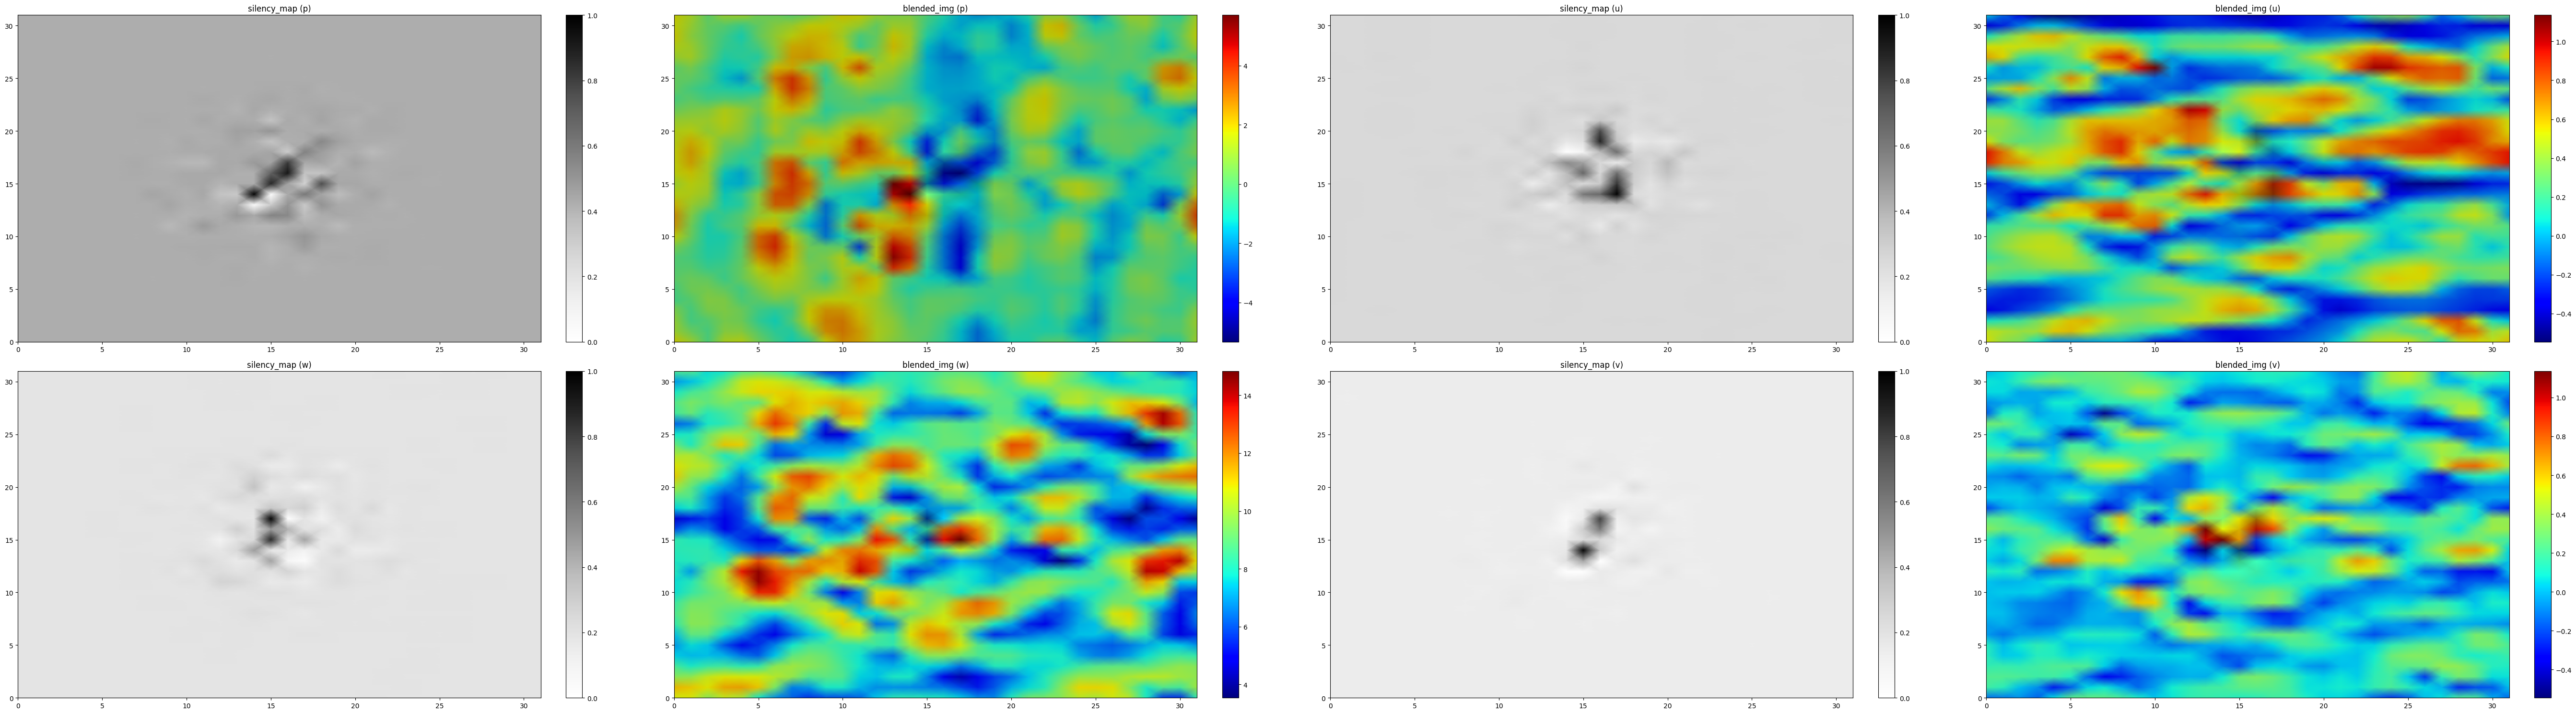

In [12]:
def plot_number(wall_test,output_val,y_test,num):
  #wall_test = wall_test.transpose(0, 3, 1, 2)
  #y_test = y_test.transpose(0, 3, 1, 2)
  wall_p = wall_test[num][0]
  wall_u = wall_test[num][1]
  wall_w = wall_test[num][2]
  wall_v = wall_test[num][3]
  pred_p = output_val[num][0]
  pred_u = output_val[num][1]
  pred_w = output_val[num][2]
  pred_v = output_val[num][3]
  y_test_p = y_test[num][0]
  y_test_u = y_test[num][1]
  y_test_w = y_test[num][2]
  y_test_v = y_test[num][3]
  return wall_p,wall_u,wall_w,wall_v,pred_p,pred_u,pred_w,pred_v,y_test_p,y_test_u,y_test_w,y_test_v
num = 57

wall_p,wall_u,wall_w,wall_v,pred_p,pred_u,pred_w,pred_v,y_test_p,y_test_u,y_test_w,y_test_v = plot_number(HR,HR_pred,LR,num)

fig = plt.figure(figsize=(55, 15))
# === サブプロット作成 & タイトル（前回どおり） ===
ax1 = fig.add_subplot(2,4,1); ax1.set_aspect(0.625); ax1.set_title("silency_map (p)")
ax2 = fig.add_subplot(2,4,2); ax2.set_aspect(0.625); ax2.set_title("blended_img (p)")
ax3 = fig.add_subplot(2,4,3); ax3.set_aspect(0.625); ax3.set_title("silency_map (u)")
ax4 = fig.add_subplot(2,4,4); ax4.set_aspect(0.625); ax4.set_title("blended_img (u)")
ax5 = fig.add_subplot(2,4,5); ax5.set_aspect(0.625); ax5.set_title("silency_map (w)")
ax6 = fig.add_subplot(2,4,6); ax6.set_aspect(0.625); ax6.set_title("blended_img (w)")
ax7 = fig.add_subplot(2,4,7); ax7.set_aspect(0.625); ax7.set_title("silency_map (v)")
ax8 = fig.add_subplot(2,4,8); ax8.set_aspect(0.625); ax8.set_title("blended_img (v)")

# === silency_map（奇数軸）は im2 と同じ仕様に変更 ===
im1 = ax1.pcolormesh(silency_norm_list[0], cmap='Greys', shading='gouraud', vmin=0, vmax=1)
cbar1 = fig.colorbar(im1, ax=ax1, orientation='vertical', fraction=0.046, pad=0.04)

# 参考として残しておきます：従来の im2 行（偶数軸なので今回は変更なし）
im2 = ax2.pcolormesh(blended_img_list[0], cmap='jet', shading='gouraud', vmin=np.max(y_test_p), vmax=np.min(y_test_p))
cbar2 = fig.colorbar(im2, ax=ax2, orientation='vertical', fraction=0.046, pad=0.04)

im3 = ax3.pcolormesh(silency_norm_list[1], cmap='Greys', shading='gouraud', vmin=0, vmax=1)
cbar3 = fig.colorbar(im3, ax=ax3, orientation='vertical', fraction=0.046, pad=0.04)

# 偶数軸（blended_img 側）は現状の描画のまま（必要なら後述の注意参照）
im4 = ax4.pcolormesh(blended_img_list[1], cmap='jet', shading='gouraud',
                     vmin=np.min(y_test_v), vmax=np.max(y_test_v))
cbar4 = fig.colorbar(im4, ax=ax4, orientation='vertical', fraction=0.046, pad=0.04)

im5 = ax5.pcolormesh(silency_norm_list[2], cmap='Greys', shading='gouraud', vmin=0, vmax=1)
cbar5 = fig.colorbar(im5, ax=ax5, orientation='vertical', fraction=0.046, pad=0.04)

im6 = ax6.pcolormesh(blended_img_list[2], cmap='jet', shading='gouraud',
                     vmin=np.min(y_test_u), vmax=np.max(y_test_u))
cbar6 = fig.colorbar(im6, ax=ax6, orientation='vertical', fraction=0.046, pad=0.04)

im7 = ax7.pcolormesh(silency_norm_list[3], cmap='Greys', shading='gouraud', vmin=0, vmax=1)
cbar7 = fig.colorbar(im7, ax=ax7, orientation='vertical', fraction=0.046, pad=0.04)

im8 = ax8.pcolormesh(blended_img_list[3], cmap='jet', shading='gouraud',
                     vmin=np.min(y_test_v), vmax=np.max(y_test_v))
cbar8 = fig.colorbar(im8, ax=ax8, orientation='vertical', fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

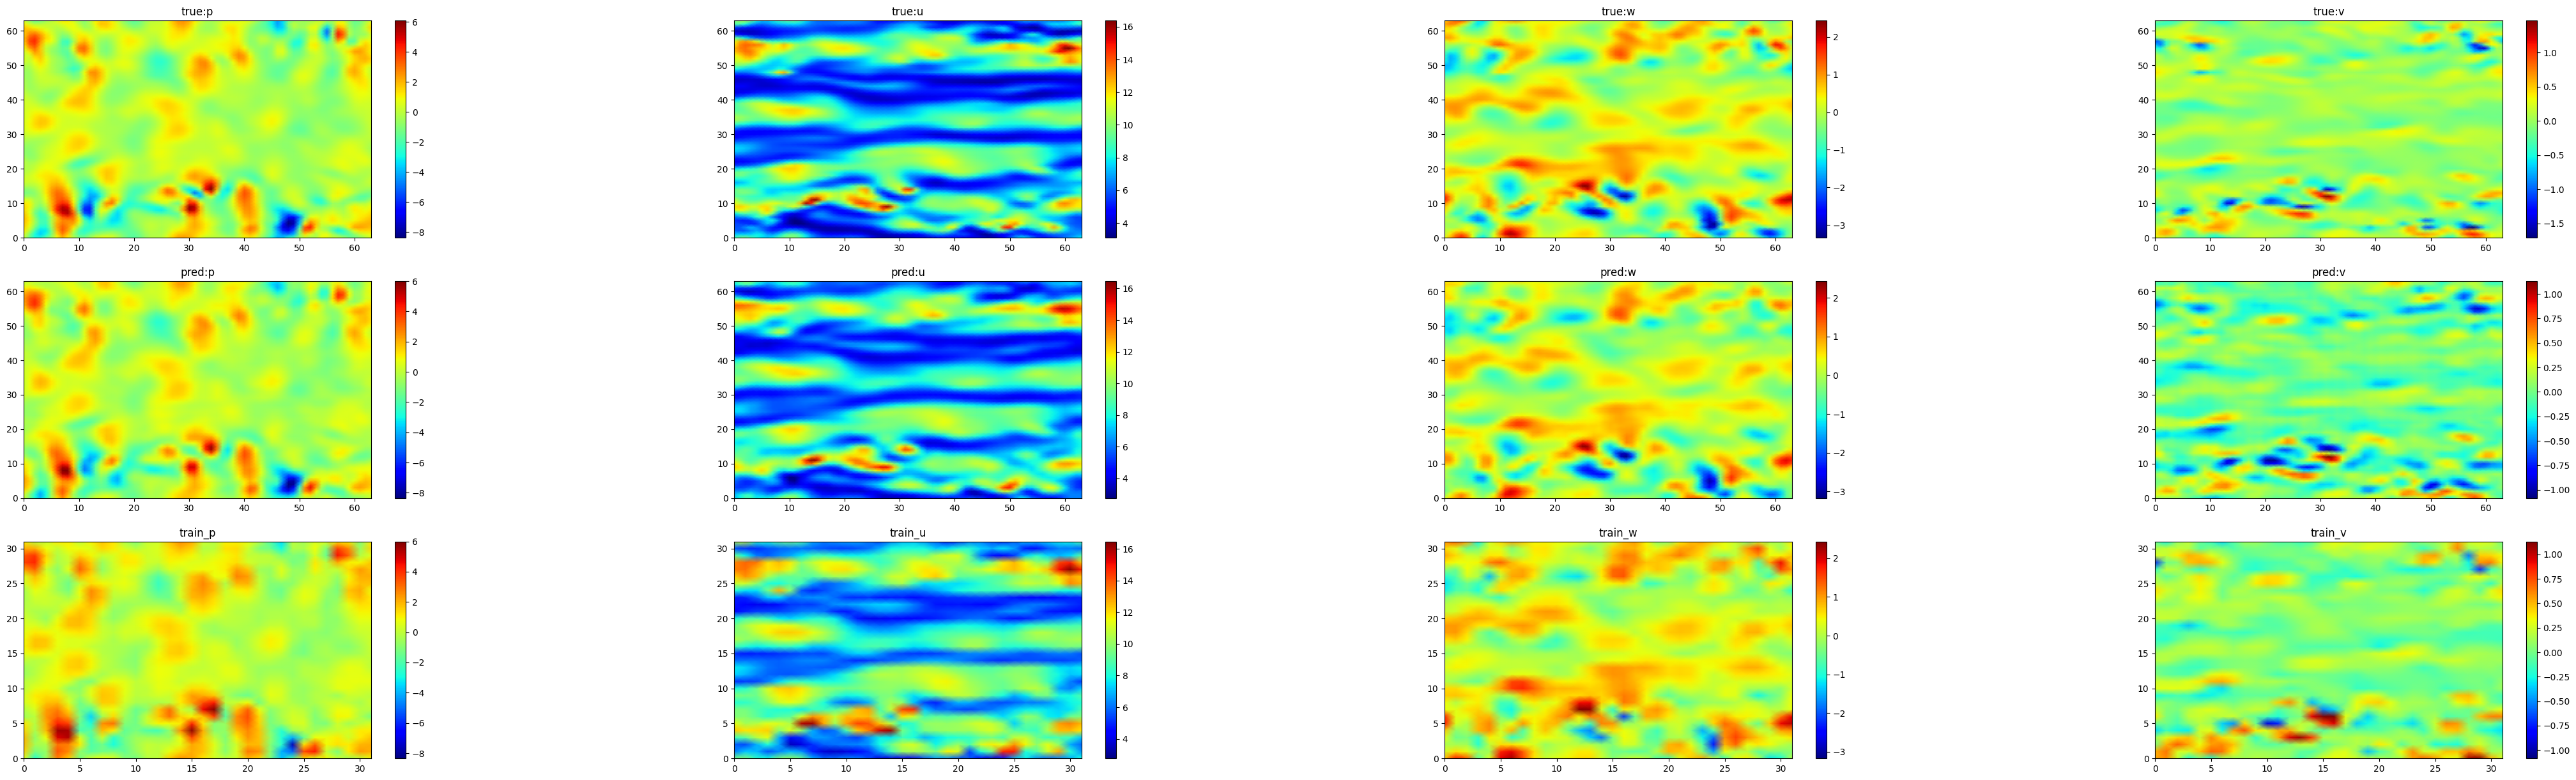

In [ ]:
def plot_number(wall_test,output_val,y_test,num):
  #wall_test = wall_test.transpose(0, 3, 1, 2)
  #y_test = y_test.transpose(0, 3, 1, 2)
  wall_p = wall_test[num][0]
  wall_u = wall_test[num][1]
  wall_w = wall_test[num][2]
  wall_v = wall_test[num][3]
  pred_p = output_val[num][0]
  pred_u = output_val[num][1]
  pred_w = output_val[num][2]
  pred_v = output_val[num][3]
  y_test_p = y_test[num][0]
  y_test_u = y_test[num][1]
  y_test_w = y_test[num][2]
  y_test_v = y_test[num][3]
  return wall_p,wall_u,wall_w,wall_v,pred_p,pred_u,pred_w,pred_v,y_test_p,y_test_u,y_test_w,y_test_v
num =2

wall_p,wall_u,wall_w,wall_v,pred_p,pred_u,pred_w,pred_v,y_test_p,y_test_u,y_test_w,y_test_v = plot_number(HR,HR_pred,LR,num)

fig = plt.figure(figsize=(55, 15))
ax1 = fig.add_subplot(3,4,1)
ax1.set_aspect(0.625)
ax1.set_title("true:p")
ax2 = fig.add_subplot(3,4,2)
ax2.set_aspect(0.625)
ax2.set_title("true:u")
ax3 = fig.add_subplot(3,4,3)
ax3.set_aspect(0.625)
ax3.set_title("true:w")
ax4 = fig.add_subplot(3,4,4)
ax4.set_aspect(0.625)
ax4.set_title("true:v")
ax5 = fig.add_subplot(3,4,5)
ax5.set_aspect(0.625)
ax5.set_title("pred:p")
ax6 = fig.add_subplot(3,4,6)
ax6.set_aspect(0.625)
ax6.set_title("pred:u")
ax7 = fig.add_subplot(3,4,7)
ax7.set_aspect(0.625)
ax7.set_title("pred:w")
ax8 = fig.add_subplot(3,4,8)
ax8.set_aspect(0.625)
ax8.set_title("pred:v")
ax9 = fig.add_subplot(3,4,9)
ax9.set_aspect(0.625)
ax9.set_title("train_p")
ax10 = fig.add_subplot(3,4,10)
ax10.set_aspect(0.625)
ax10.set_title("train_u")
ax11 = fig.add_subplot(3,4,11)
ax11.set_aspect(0.625)
ax11.set_title("train_w")
ax12 = fig.add_subplot(3,4,12)
ax12.set_aspect(0.625)
ax12.set_title("train_v")

im1=ax1.pcolormesh(wall_p.T, cmap='jet', shading='gouraud', vmax=np.max(wall_p), vmin=np.min(wall_p))
cbar1 = fig.colorbar(im1, ax=ax1, orientation='vertical', fraction=0.046, pad=0.04)
im2=ax2.pcolormesh(wall_u.T, cmap='jet', shading='gouraud', vmax=np.max(wall_u), vmin=np.min(wall_u))
cbar2 = fig.colorbar(im2, ax=ax2, orientation='vertical', fraction=0.046, pad=0.04)
im3=ax3.pcolormesh(wall_w.T, cmap='jet', shading='gouraud', vmax=np.max(wall_w), vmin=np.min(wall_w))
cbar3 = fig.colorbar(im3, ax=ax3, orientation='vertical', fraction=0.046, pad=0.04)
im4=ax4.pcolormesh(wall_v.T, cmap='jet', shading='gouraud', vmax=np.max(wall_v), vmin=np.min(wall_v))
cbar4 = fig.colorbar(im4, ax=ax4, orientation='vertical', fraction=0.046, pad=0.04)
im5=ax5.pcolormesh(pred_p, cmap='jet', shading='gouraud', vmax=np.max(pred_p), vmin=np.min(pred_p))
cbar5 = fig.colorbar(im5, ax=ax5, orientation='vertical', fraction=0.046, pad=0.04)
im6=ax6.pcolormesh(pred_u, cmap='jet', shading='gouraud', vmax=np.max(pred_u), vmin=np.min(pred_u))
cbar6= fig.colorbar(im6, ax=ax6, orientation='vertical', fraction=0.046, pad=0.04)
im7=ax7.pcolormesh(pred_w, cmap='jet', shading='gouraud', vmax=np.max(pred_w), vmin=np.min(pred_w))
cbar7 = fig.colorbar(im7, ax=ax7, orientation='vertical', fraction=0.046, pad=0.04)
im8=ax8.pcolormesh(pred_v, cmap='jet', shading='gouraud', vmax=np.max(pred_v), vmin=np.min(pred_v))
cbar8 = fig.colorbar(im8, ax=ax8, orientation='vertical', fraction=0.046, pad=0.04)
im9=ax9.pcolormesh(y_test_p.T, cmap='jet', shading='gouraud', vmax=np.max(pred_p), vmin=np.min(pred_p))
cbar9 = fig.colorbar(im9, ax=ax9, orientation='vertical', fraction=0.046, pad=0.04)
im10=ax10.pcolormesh(y_test_u.T, cmap='jet', shading='gouraud', vmax=np.max(pred_u), vmin=np.min(pred_u))
cbar10 = fig.colorbar(im10, ax=ax10, orientation='vertical', fraction=0.046, pad=0.04)
im11=ax11.pcolormesh(y_test_w.T, cmap='jet', shading='gouraud', vmax=np.max(pred_w), vmin=np.min(pred_w))
cbar11 = fig.colorbar(im11, ax=ax11, orientation='vertical', fraction=0.046, pad=0.04)
im12=ax12.pcolormesh(y_test_v.T, cmap='jet', shading='gouraud', vmax=np.max(pred_v), vmin=np.min(pred_v))
cbar12 = fig.colorbar(im12, ax=ax12, orientation='vertical', fraction=0.046, pad=0.04)
plt.show()

In [ ]:
print(silency_norm_list[0])